In [1]:
#1.Importing the required libraries.
#import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#2.Loading the data from the CSV.
#read the excel file

import pandas as pd

df = pd.read_excel("orders-data.xlsx")

In [3]:
#3.Displaying the first 5 rows of the DataFrame.

df.head()

,USER_ID,ORDER_ID,PURCHASE_TS,SHIP_TS,PRODUCT_NAME,PRODUCT_ID,USD_PRICE,PURCHASE_PLATFORM,MARKETING_CHANNEL,ACCOUNT_CREATION_METHOD,COUNTRY_CODE
0,2c06175e,0001328c3c220830,2020-12-24 00:00:00,2020-12-13,Nintendo Switch,e682,168.00,website,affiliate,unknown,US
1,ee8e5bc2,0002af7a5c6100772,2020-10-01 00:00:00,2020-09-21,Nintendo Switch,e682,160.61,website,direct,desktop,DE
2,9eb4efe0,0002b8350e167074,2020-04-21 00:00:00,2020-02-16,Nintendo Switch,8d0d,151.20,website,direct,desktop,US
3,cac7cbaf,0006d06b98385729,2020-04-07 00:00:00,2020-04-04,Sony PlayStation 5 Bundle,54ed,1132.82,website,direct,desktop,AU
4,6b0230bc,00097279a2f46150,2020-11-24 00:00:00,2020-08-02,Nintendo Switch,8d0d,33.89,website,direct,desktop,TR


In [4]:
#4.Displaying the number of rows and columns in the DataFrame.

df.shape

(21864, 11)

In [5]:
#5.Displaying the details of the DataFrame like - data types, non-null columns, memory usage and so on.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21864 entries, 0 to 21863
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   USER_ID                  21864 non-null  object        
 1   ORDER_ID                 21864 non-null  object        
 2   PURCHASE_TS              21864 non-null  object        
 3   SHIP_TS                  21864 non-null  datetime64[ns]
 4   PRODUCT_NAME             21864 non-null  object        
 5   PRODUCT_ID               21864 non-null  object        
 6   USD_PRICE                21859 non-null  float64       
 7   PURCHASE_PLATFORM        21864 non-null  object        
 8   MARKETING_CHANNEL        21781 non-null  object        
 9   ACCOUNT_CREATION_METHOD  21781 non-null  object        
 10  COUNTRY_CODE             21826 non-null  object        
dtypes: datetime64[ns](1), float64(1), object(9)
memory usage: 1.8+ MB


In [6]:
#6.Displaying the data types of the columns.
df.dtypes

USER_ID                            object
ORDER_ID                           object
PURCHASE_TS                        object
SHIP_TS                    datetime64[ns]
PRODUCT_NAME                       object
PRODUCT_ID                         object
USD_PRICE                         float64
PURCHASE_PLATFORM                  object
MARKETING_CHANNEL                  object
ACCOUNT_CREATION_METHOD            object
COUNTRY_CODE                       object
dtype: object

In [7]:
#7.Displaying the 5-Number Summary of the Numeric-columns.
df.describe()

,SHIP_TS,USD_PRICE
count,21864,21859.000000
mean,2020-04-15 16:04:48.474204160,281.406583
min,2018-10-18 00:00:00,0.000000
25%,2019-11-12 00:00:00,126.000000
50%,2020-05-23 00:00:00,168.000000
75%,2020-10-06 00:00:00,357.000000
max,2021-11-16 00:00:00,3146.880000
std,NaN,366.296410


In [8]:
#8.Checking for missing values (NaN values) & replace with mean.
#Check null values

df.isnull().any()

USER_ID                    False
ORDER_ID                   False
PURCHASE_TS                False
SHIP_TS                    False
PRODUCT_NAME               False
PRODUCT_ID                 False
USD_PRICE                   True
PURCHASE_PLATFORM          False
MARKETING_CHANNEL           True
ACCOUNT_CREATION_METHOD     True
COUNTRY_CODE                True
dtype: bool

In [9]:
#Check how many null values are there

df.isnull().sum()[df.isnull().sum() > 0]

USD_PRICE                   5
MARKETING_CHANNEL          83
ACCOUNT_CREATION_METHOD    83
COUNTRY_CODE               38
dtype: int64

In [11]:
#Replace missing values with Mean

df['USD_PRICE'] = df['USD_PRICE'].fillna(df['USD_PRICE'].mean())

In [12]:
df['MARKETING_CHANNEL'] = df['MARKETING_CHANNEL'].fillna('Unknown')
df['ACCOUNT_CREATION_METHOD'] = df['ACCOUNT_CREATION_METHOD'].fillna('Unknown')
df['COUNTRY_CODE'] = df['COUNTRY_CODE'].fillna('Unknown')

In [13]:
df.isnull().sum()

USER_ID                    0
ORDER_ID                   0
PURCHASE_TS                0
SHIP_TS                    0
PRODUCT_NAME               0
PRODUCT_ID                 0
USD_PRICE                  0
PURCHASE_PLATFORM          0
MARKETING_CHANNEL          0
ACCOUNT_CREATION_METHOD    0
COUNTRY_CODE               0
dtype: int64

In [14]:
#9.Check or duplicates in the DataFrames if any then remove.
#Check duplicate values

print("Duplicate values:", df.duplicated().sum())

Duplicate values: 35


In [15]:
#Remove duplicate values

df.drop_duplicates(inplace=True)

In [16]:
print("Duplicate values after removing:", df.duplicated().sum())

Duplicate values after removing: 0


In [19]:
#10.Perform Casting columns to appropriate data types where applicable.
# 10. Perform Casting columns to appropriate data types

df['PURCHASE_TS'] = pd.to_datetime(df['PURCHASE_TS'], errors='coerce')
df['SHIP_TS'] = pd.to_datetime(df['SHIP_TS'], errors='coerce')

# Fill invalid/missing dates
df['PURCHASE_TS'] = df['PURCHASE_TS'].fillna(
    df['PURCHASE_TS'].mode()[0]
)

df['SHIP_TS'] = df['SHIP_TS'].fillna(
    df['SHIP_TS'].mode()[0]
)

print(df.dtypes)

USER_ID                            object
ORDER_ID                           object
PURCHASE_TS                datetime64[ns]
SHIP_TS                    datetime64[ns]
PRODUCT_NAME                       object
PRODUCT_ID                         object
USD_PRICE                         float64
PURCHASE_PLATFORM                  object
MARKETING_CHANNEL                  object
ACCOUNT_CREATION_METHOD            object
COUNTRY_CODE                       object
dtype: object


In [20]:
#Data Visualization on the DataFrame

PRODUCT_NAME
27in 4K gaming monitor            1.932738e+06
Nintendo Switch                   1.658718e+06
Sony PlayStation 5 Bundle         1.589244e+06
Lenovo IdeaPad Gaming 3           7.355066e+05
JBL Quantum 100 Gaming Headset    9.647908e+04
Acer Nitro V Gaming Laptop        6.566118e+04
Dell Gaming Mouse                 3.761564e+04
27inches 4k gaming monitor        2.130935e+04
Razer Pro Gaming Headset          8.842300e+02
Name: USD_PRICE, dtype: float64


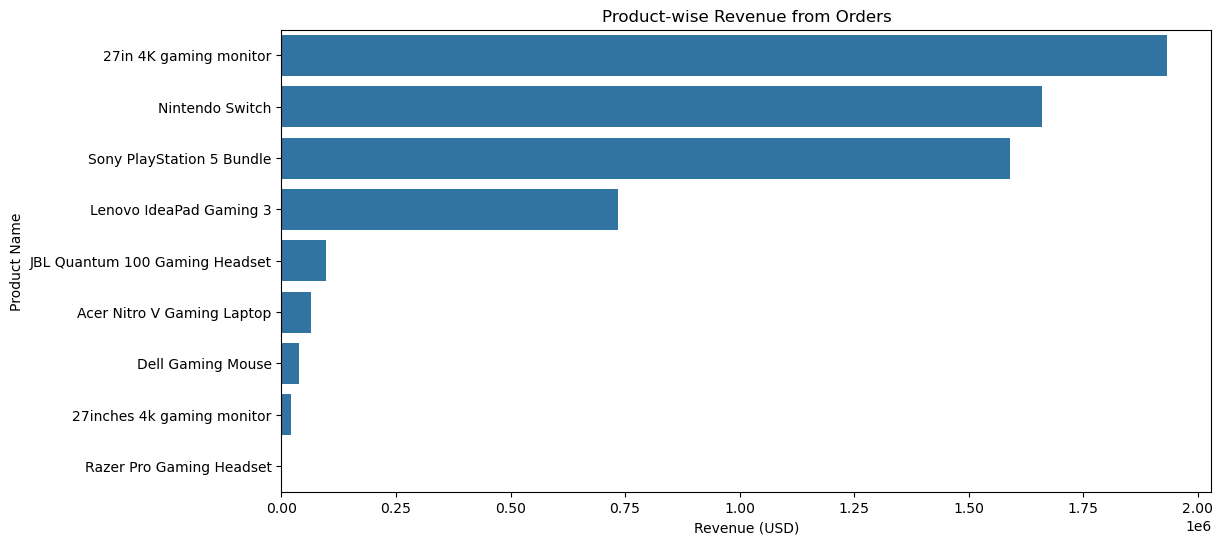

In [31]:
#1.Design Product-wise Revenue from Orders.
#Product-wise Revenue from Orders

product_revenue = df.groupby('PRODUCT_NAME')['USD_PRICE'].sum().sort_values(
    ascending=False
)

print(product_revenue)

plt.figure(figsize=(12,6))

sns.barplot(
    x=product_revenue.values,
    y=product_revenue.index
)

plt.title('Product-wise Revenue from Orders')
plt.xlabel('Revenue (USD)')
plt.ylabel('Product Name')

plt.show()

MARKETING_CHANNEL
direct          17403
email            3256
affiliate         717
social media      323
Unknown            83
unknown            47
Name: count, dtype: int64


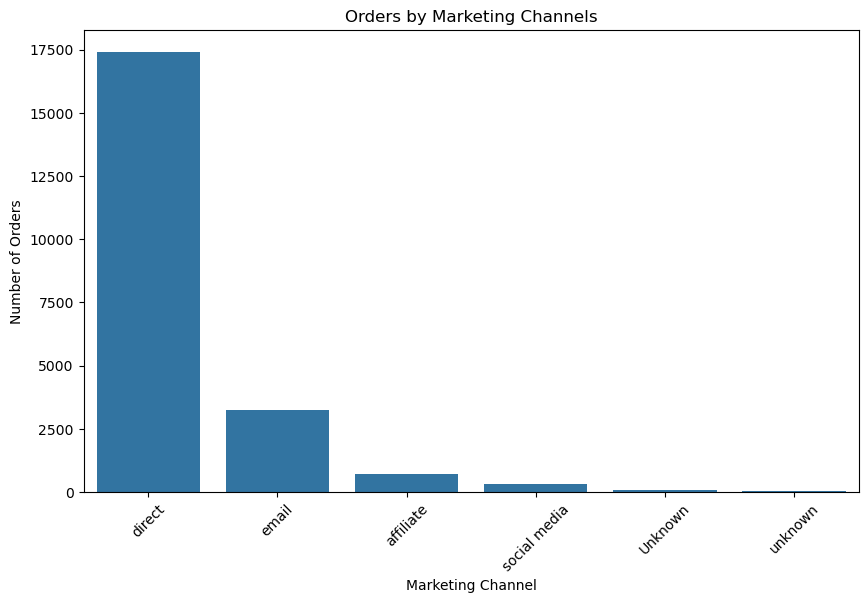

In [32]:
#2. Design Orders by Marketing Channels.
#Orders by Marketing Channels

marketing_orders = df['MARKETING_CHANNEL'].value_counts()

print(marketing_orders)

plt.figure(figsize=(10,6))

sns.barplot(
    x=marketing_orders.index,
    y=marketing_orders.values
)

plt.title('Orders by Marketing Channels')
plt.xlabel('Marketing Channel')
plt.ylabel('Number of Orders')

plt.xticks(rotation=45)

plt.show()

SHIP_TS
2019-01-06     69
2019-01-13    104
2019-01-20    119
2019-01-27    110
2019-02-03    118
             ... 
2021-10-24      0
2021-10-31      0
2021-11-07      0
2021-11-14      0
2021-11-21      1
Freq: W-SUN, Length: 151, dtype: int64


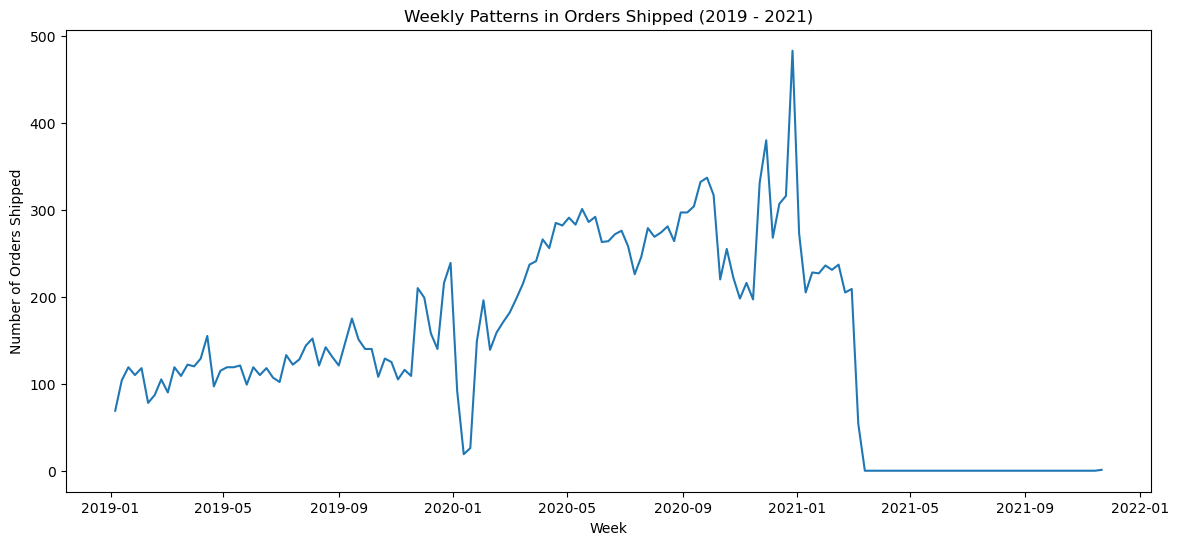

In [30]:
#3.Design Weekly Patterns in Oders Shipped (2019 - 2021).
#Weekly Patterns in Orders Shipped

weekly_orders = (
    df.set_index('SHIP_TS')
      .sort_index()
      .loc['2019':'2021']
      .resample('W')
      .size()
)

print(weekly_orders)

plt.figure(figsize=(14,6))
plt.plot(weekly_orders)

plt.title('Weekly Patterns in Orders Shipped (2019 - 2021)')
plt.xlabel('Week')
plt.ylabel('Number of Orders Shipped')
plt.show()

PURCHASE_TS
2019     6611
2020    13371
2021     1847
Name: ORDER_ID, dtype: int64


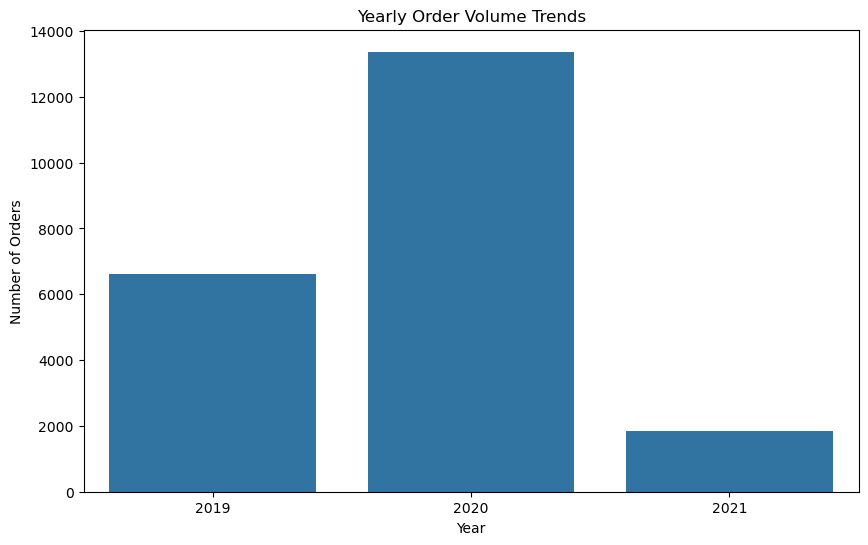

In [33]:
#4.Design Yearly Order Volume Trends.

yearly_orders = df.groupby(df['PURCHASE_TS'].dt.year)['ORDER_ID'].count()

print(yearly_orders)

plt.figure(figsize=(10,6))
sns.barplot(x=yearly_orders.index, y=yearly_orders.values)

plt.title('Yearly Order Volume Trends')
plt.xlabel('Year')
plt.ylabel('Number of Orders')
plt.show()

SHIP_TS
2018       46
2019     6706
2020    13144
2021     1933
Name: ORDER_ID, dtype: int64


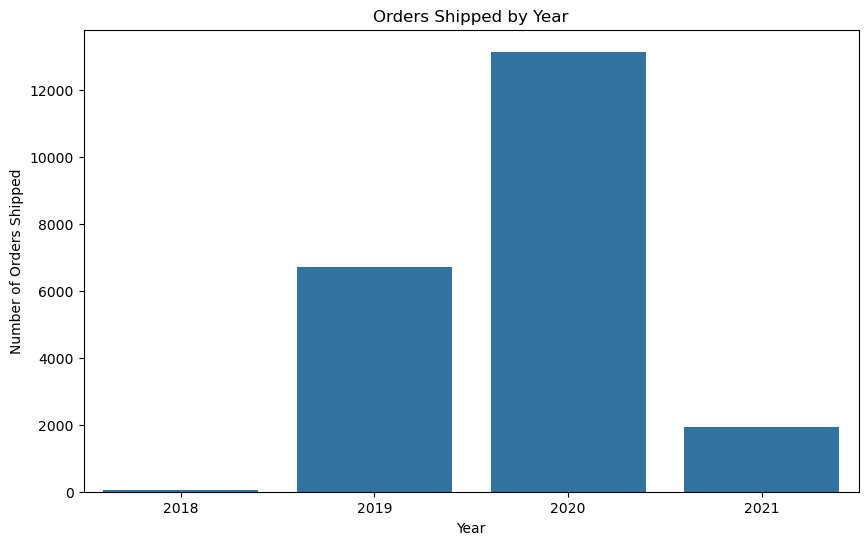

In [34]:
#5.Design Orders Shipped by Year.

shipped_by_year = df.groupby(df['SHIP_TS'].dt.year)['ORDER_ID'].count()

print(shipped_by_year)

plt.figure(figsize=(10,6))
sns.barplot(x=shipped_by_year.index, y=shipped_by_year.values)

plt.title('Orders Shipped by Year')
plt.xlabel('Year')
plt.ylabel('Number of Orders Shipped')
plt.show()

PRODUCT_NAME
27in 4K gaming monitor            1.932738e+06
Nintendo Switch                   1.658718e+06
Sony PlayStation 5 Bundle         1.589244e+06
Lenovo IdeaPad Gaming 3           7.355066e+05
JBL Quantum 100 Gaming Headset    9.647908e+04
Acer Nitro V Gaming Laptop        6.566118e+04
Dell Gaming Mouse                 3.761564e+04
27inches 4k gaming monitor        2.130935e+04
Razer Pro Gaming Headset          8.842300e+02
Name: USD_PRICE, dtype: float64


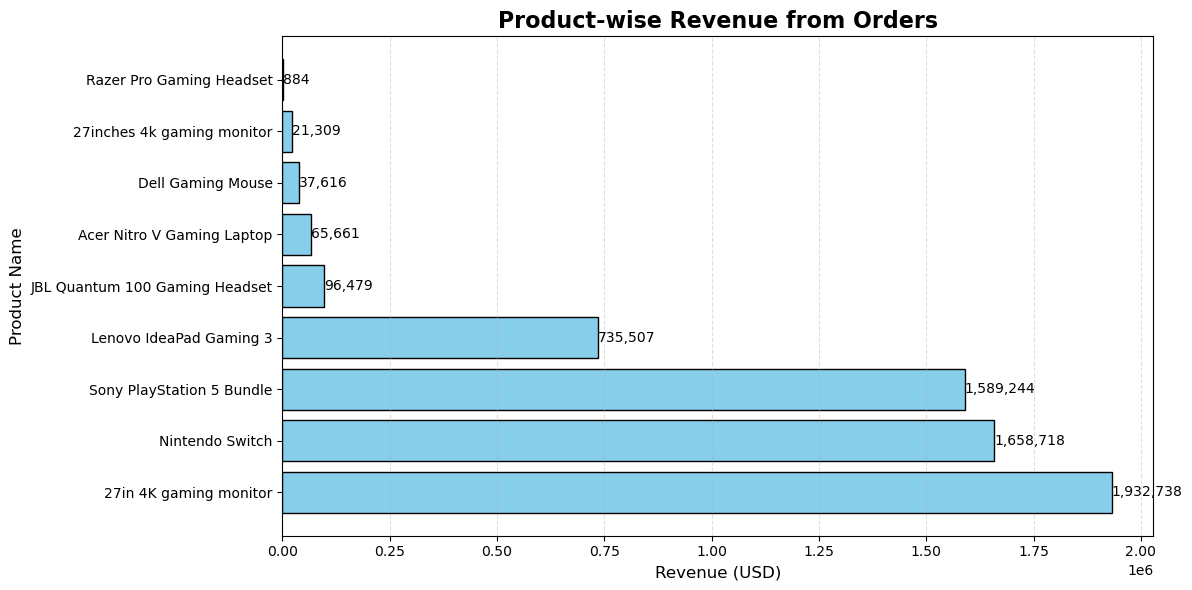

In [35]:
# 1. Product-wise Revenue from Orders

product_revenue = df.groupby('PRODUCT_NAME')['USD_PRICE'].sum().sort_values(ascending=False)

print(product_revenue)

plt.figure(figsize=(12,6))

bars = plt.barh(
    product_revenue.index,
    product_revenue.values,
    color='skyblue',
    edgecolor='black'
)

plt.title('Product-wise Revenue from Orders', fontsize=16, fontweight='bold')
plt.xlabel('Revenue (USD)', fontsize=12)
plt.ylabel('Product Name', fontsize=12)

# Add values on bars
for bar in bars:
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f'{bar.get_width():,.0f}',
        va='center'
    )

plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

MARKETING_CHANNEL
direct          17403
email            3256
affiliate         717
social media      323
Unknown            83
unknown            47
Name: count, dtype: int64


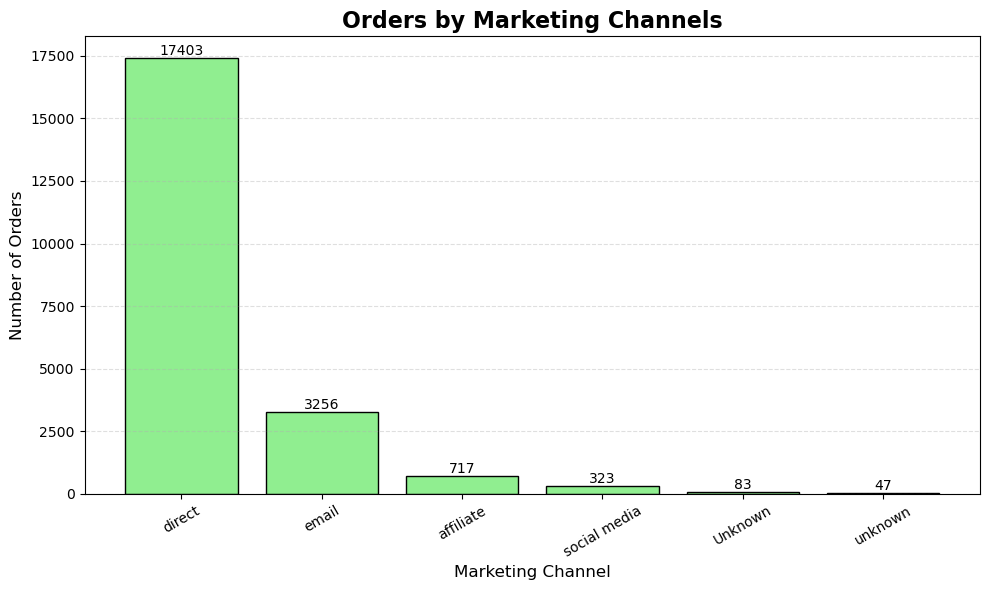

In [36]:
# 2. Orders by Marketing Channels

marketing_orders = df['MARKETING_CHANNEL'].value_counts()

print(marketing_orders)

plt.figure(figsize=(10,6))

bars = plt.bar(
    marketing_orders.index,
    marketing_orders.values,
    color='lightgreen',
    edgecolor='black'
)

plt.title('Orders by Marketing Channels', fontsize=16, fontweight='bold')
plt.xlabel('Marketing Channel', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)

plt.xticks(rotation=30)

# Add values on bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha='center',
        va='bottom'
    )

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

SHIP_TS
2019-01-06     69
2019-01-13    104
2019-01-20    119
2019-01-27    110
2019-02-03    118
             ... 
2021-10-24      0
2021-10-31      0
2021-11-07      0
2021-11-14      0
2021-11-21      1
Freq: W-SUN, Length: 151, dtype: int64


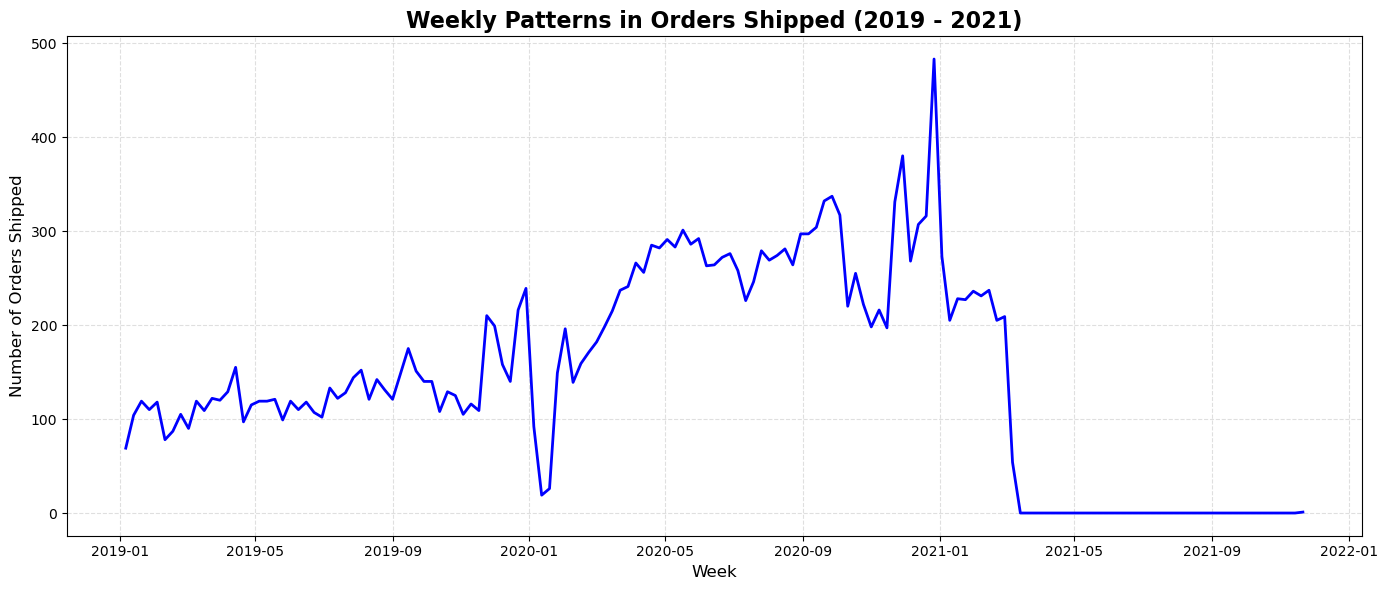

In [37]:
# 3. Weekly Patterns in Orders Shipped (2019 - 2021)

weekly_orders = (
    df.set_index('SHIP_TS')
      .sort_index()
      .loc['2019':'2021']
      .resample('W')
      .size()
)

print(weekly_orders)

plt.figure(figsize=(14,6))

plt.plot(
    weekly_orders.index,
    weekly_orders.values,
    color='blue',
    linewidth=2
)

plt.title(
    'Weekly Patterns in Orders Shipped (2019 - 2021)',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Week', fontsize=12)
plt.ylabel('Number of Orders Shipped', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

PURCHASE_TS
2019     6611
2020    13371
2021     1847
Name: ORDER_ID, dtype: int64


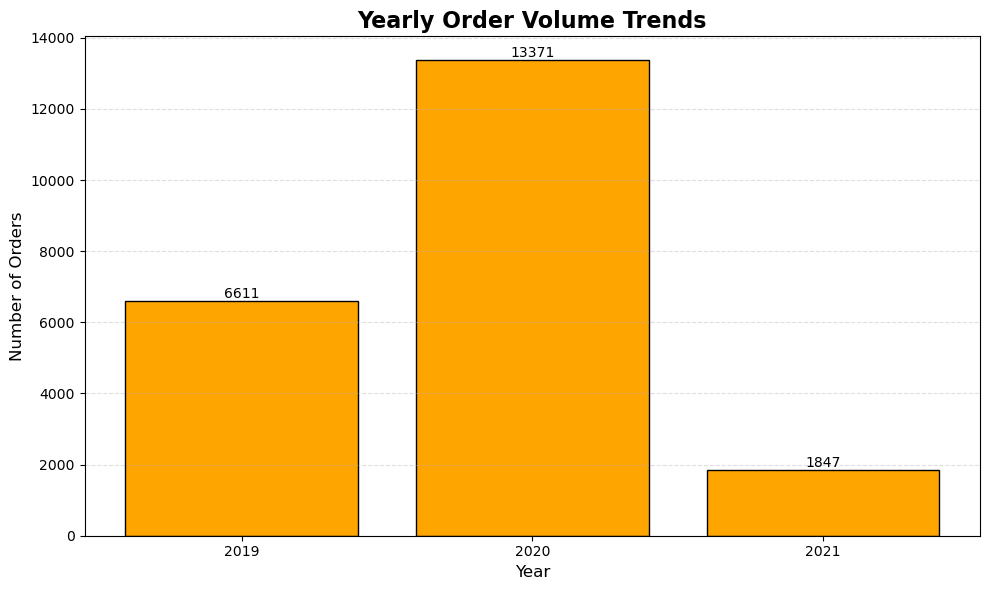

In [38]:
# 4. Yearly Order Volume Trends

yearly_orders = df.groupby(
    df['PURCHASE_TS'].dt.year
)['ORDER_ID'].count()

print(yearly_orders)

plt.figure(figsize=(10,6))

bars = plt.bar(
    yearly_orders.index.astype(str),
    yearly_orders.values,
    color='orange',
    edgecolor='black'
)

plt.title(
    'Yearly Order Volume Trends',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)

# Add values on bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha='center',
        va='bottom'
    )

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

SHIP_TS
2018       46
2019     6706
2020    13144
2021     1933
Name: ORDER_ID, dtype: int64


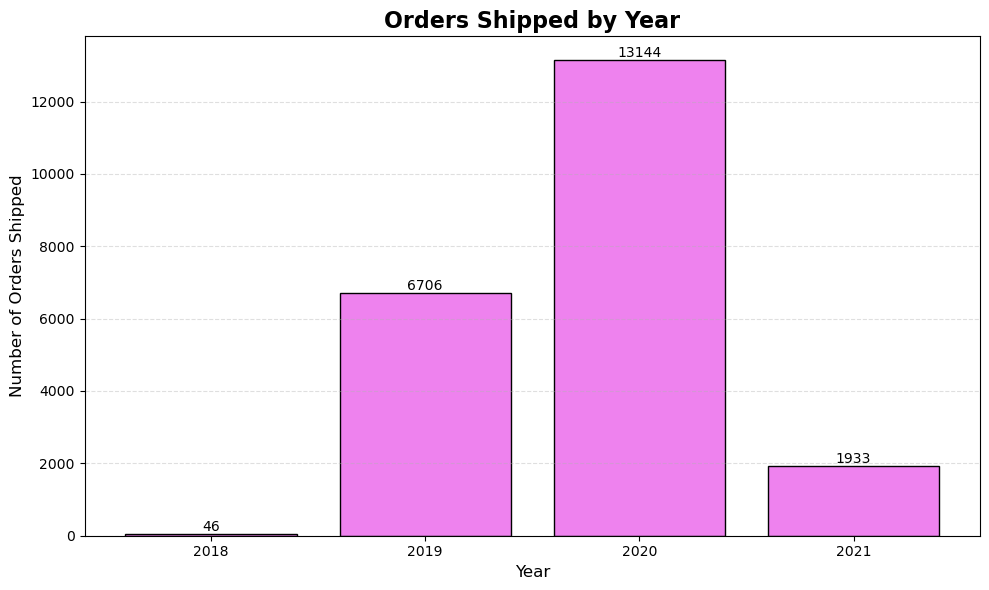

In [39]:
# 5. Orders Shipped by Year

shipped_by_year = df.groupby(
    df['SHIP_TS'].dt.year
)['ORDER_ID'].count()

print(shipped_by_year)

plt.figure(figsize=(10,6))

bars = plt.bar(
    shipped_by_year.index.astype(str),
    shipped_by_year.values,
    color='violet',
    edgecolor='black'
)

plt.title(
    'Orders Shipped by Year',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Orders Shipped', fontsize=12)

# Add values on bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha='center',
        va='bottom'
    )

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()